# Unit 2 – Assignment 4: Statistical Analysis of the Titanic Dataset
**Group members:** Daniyah , Jana , Ragad , Suliman



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Load the data.
try:
    df = pd.read_csv("titanic.csv")
except FileNotFoundError:
    url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    df = pd.read_csv(url)

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Task 1 – Dataset Exploration

In [ ]:
rows, cols = df.shape
print(f"Rows: {rows}")
print(f"Columns: {cols}")
print()
print("Column names:", list(df.columns))

Rows: 891
Columns: 12

Column names: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [ ]:
print("Data types:")
print(df.dtypes)

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [ ]:
missing = pd.DataFrame(df.isnull().sum())
print(missing)

               0
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age          177
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin        687
Embarked       2



1. The dataset has **891 rows** and **12 columns**.
2. Columns: PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked.
3. Data types are shown in the output above (integers, floats, and text/object columns).
4. Missing values: **Age (177)**, **Cabin (687)**, **Embarked (2)**.
5. **Description:** The dataset records 891 passengers of the RMS Titanic, which sank in 1912. Each row is one passenger, with demographics (sex, age), travel details (ticket class, fare, port of embarkation, cabin), and family information (siblings/spouses and parents/children aboard). The `Survived` column says whether the passenger lived (1) or died (0), which makes this a classic binary classification problem. Some columns, especially `Cabin` and `Age`, have many missing values.

## Task 2 – Variable Classification

In [ ]:
classification = pd.DataFrame([
    ["PassengerId", "Categorical", "Nominal", "Identifier only; numbers are labels, arithmetic on them is meaningless"],
    ["Survived",    "Categorical", "Nominal",    "0 = died, 1 = survived (binary label)"],
    ["Pclass",      "Categorical", "Ordinal",    "1st > 2nd > 3rd class; ordered categories"],
    ["Name",        "Categorical", "Nominal",    "Text label, unique per passenger"],
    ["Sex",         "Categorical", "Nominal",    "male / female, no order"],
    ["Age",         "Numerical",   "Continuous", "Can take fractional values (e.g. 0.42)"],
    ["SibSp",       "Numerical",   "Discrete",   "Count of siblings/spouses aboard"],
    ["Parch",       "Numerical",   "Discrete",   "Count of parents/children aboard"],
    ["Ticket",      "Categorical", "Nominal",    "Ticket code, no order"],
    ["Fare",        "Numerical",   "Continuous", "Money paid, any positive value"],
    ["Cabin",       "Categorical", "Nominal",    "Cabin code, no order"],
    ["Embarked",    "Categorical", "Nominal",    "C / Q / S port, no order"],
], columns=["Variable", "Type", "Classification", "Reason"])
classification

,Variable,Type,Classification,Reason
0,PassengerId,Numerical,Discrete,Just an ID number; carries no real meaning
1,Survived,Categorical,Nominal,"0 = died, 1 = survived (binary label)"
2,Pclass,Categorical,Ordinal,1st > 2nd > 3rd class; ordered categories
3,Name,Categorical,Nominal,"Text label, unique per passenger"
4,Sex,Categorical,Nominal,"male / female, no order"
5,Age,Numerical,Continuous,Can take fractional values (e.g. 0.42)
6,SibSp,Numerical,Discrete,Count of siblings/spouses aboard
7,Parch,Numerical,Discrete,Count of parents/children aboard
8,Ticket,Categorical,Nominal,"Ticket code, no order"
9,Fare,Numerical,Continuous,"Money paid, any positive value"


## Task 3 – Features and Target

1. **Target variable:** `Survived`.
2. **Input features:** `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked`
3. **Why dependent?** `Survived` is the outcome we want to predict. Its value *depends on* the passenger's characteristics (sex, class, age, and so on).
4. **Why independent?** The other variables are the inputs. Their values are recorded before the outcome and do not depend on survival. We use them to explain or predict the target.

## Task 4 – Population and Sampling

In [ ]:
population = df
random_sample = df.sample(frac=0.30, random_state=42)

# Stratified sample: take 30% from each Survived group
stratified_sample = pd.concat(
    [g.sample(frac=0.30, random_state=42) for _, g in df.groupby("Survived")]
)

sizes = pd.DataFrame({
    "Dataset": ["Population", "Random sample (30%)", "Stratified sample (30%)"],
    "Size": [len(population), len(random_sample), len(stratified_sample)]
})
print(sizes.to_string(index=False))

                Dataset  Size
             Population   891
    Random sample (30%)   267
Stratified sample (30%)   268


In [ ]:
compare = pd.DataFrame({
    "Population": population["Survived"].value_counts(normalize=True),
    "Random 30%": random_sample["Survived"].value_counts(normalize=True),
    "Stratified 30%": stratified_sample["Survived"].value_counts(normalize=True),
}).round(4) * 100
compare.index = ["Died (0)", "Survived (1)"]
print("Class distribution (%):")
compare

Class distribution (%):


,Population,Random 30%,Stratified 30%
Died (0),61.62,58.8,61.57
Survived (1),38.38,41.2,38.43


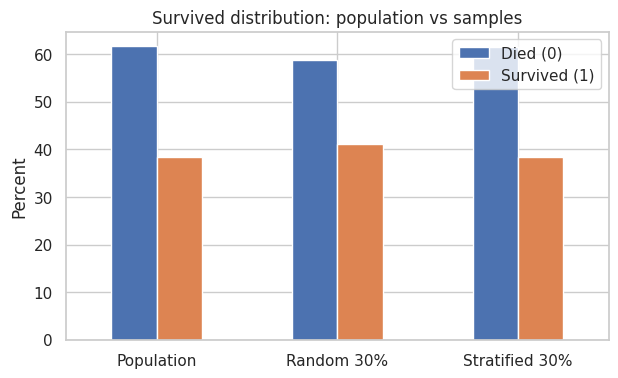

In [ ]:
compare.T.plot(kind="bar", figsize=(7, 4))
plt.title("Survived distribution: population vs samples")
plt.ylabel("Percent")
plt.xticks(rotation=0)
plt.show()


1. **Population:** all 891 passengers in the dataset (we treat it as the whole population).
2. **Sample:** a subset drawn from the population. Here we have two: a random sample and a stratified sample, each 30% of the data (about 267 rows).
3. Both samples are about **30% of the population size** (267 vs 891). See the table above.
4. **The stratified sample** preserves the original class distribution (about 61.6% died / 38.4% survived) almost exactly, because it samples 30% *within each class*. The simple random sample can drift (in our run it gave about 58.8% / 41.2%) because it relies on chance.
5. **Why representative sampling matters in ML:** a model learns patterns from the sample. If the sample over- or under-represents a class, the model learns a biased picture and performs badly on real data. This is especially serious with imbalanced classes, where a random sample might contain too few examples of the minority class.

## Task 5 – Descriptive Statistics


In [ ]:
# We use three numerical variables: Age, Fare, and SibSp.
vars_ = ["Age", "Fare", "SibSp"]
rows = []
for v in vars_:
    s = df[v].dropna()
    rows.append({
        "Variable": v,
        "Mean": s.mean(),
        "Median": s.median(),
        "Mode": s.mode().iloc[0],
        "Min": s.min(),
        "Max": s.max(),
        "Range": s.max() - s.min(),
        "Variance": s.var(),
        "Std Dev": s.std(),
    })
stats = pd.DataFrame(rows).set_index("Variable").round(3)
stats

,Mean,Median,Mode,Min,Max,Range,Variance,Std Dev
Variable,,,,,,,,
Age,29.699,28.000,24.00,0.42,80.000,79.580,211.019,14.526
Fare,32.204,14.454,8.05,0.00,512.329,512.329,2469.437,49.693
SibSp,0.523,0.000,0.00,0.00,8.000,8.000,1.216,1.103


In [ ]:
print("Highest mean:      ", stats["Mean"].idxmax())
print("Highest std dev:   ", stats["Std Dev"].idxmax())
print("Highest variance:  ", stats["Variance"].idxmax())
print()
print("Skewness:")
print(df[vars_].skew().round(3))

Highest mean:       Fare
Highest std dev:    Fare
Highest variance:   Fare

Skewness:
Age      0.389
Fare     4.787
SibSp    3.695
dtype: float64



1. **Highest average:** `Fare` (about 32.2), compared with Age (about 29.7) and SibSp (about 0.52).
2. **Greatest variability:** `Fare` (std about 49.7, variance about 2469). Its range is 0 to 512.
3. **Mean vs median:**
   - **Age:** close (29.7 vs 28.0), so the distribution is roughly symmetric.
   - **Fare:** far apart (32.2 vs 14.45). The mean is more than double the median.
   - **SibSp:** mean 0.52 vs median 0, also not equal, since most passengers travelled with no siblings or spouse.
4. **Interpretation:** When mean > median, the distribution is **right-skewed**: a few very large values pull the mean up. `Fare` is strongly right-skewed (skewness about 4.8), `SibSp` is right-skewed too (about 3.7), and `Age` is close to symmetric (about 0.39).

## Task 6 – Distribution and Outlier Analysis


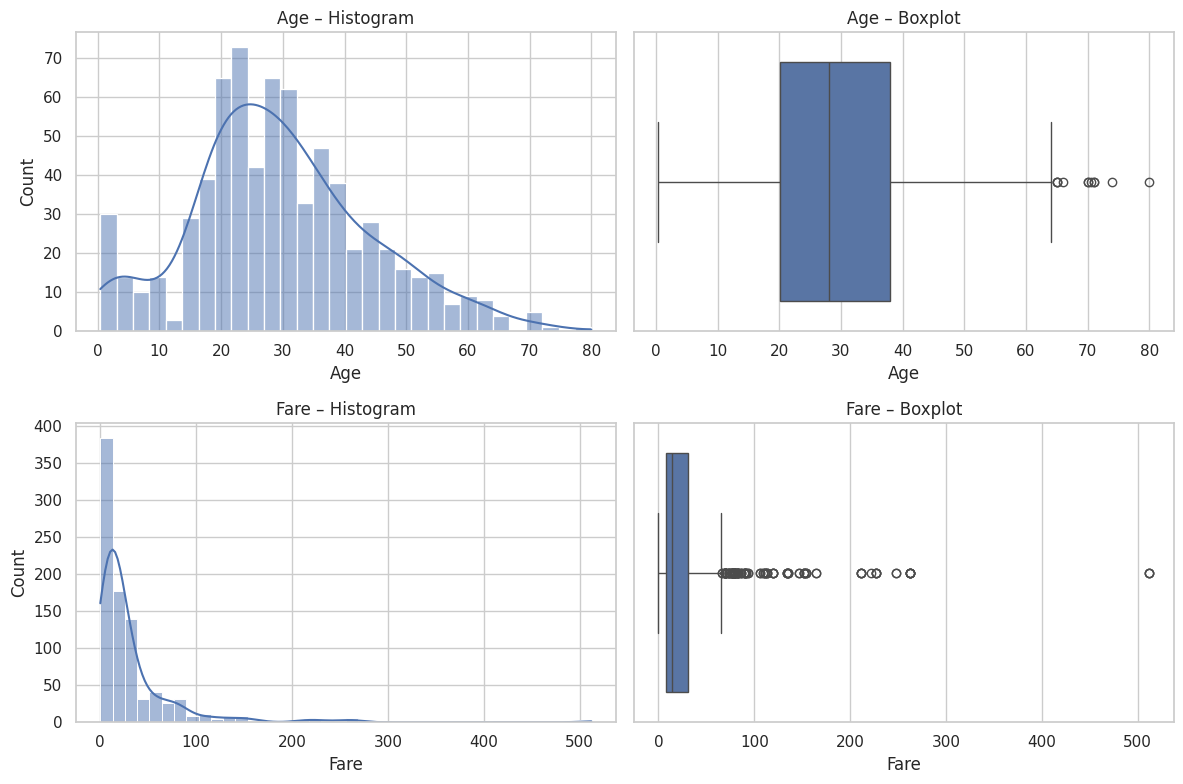

In [ ]:
# We use Age and Fare.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["Age"].dropna(), bins=30, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Age – Histogram")
sns.boxplot(x=df["Age"].dropna(), ax=axes[0, 1])
axes[0, 1].set_title("Age – Boxplot")

sns.histplot(df["Fare"], bins=40, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Fare – Histogram")
sns.boxplot(x=df["Fare"], ax=axes[1, 1])
axes[1, 1].set_title("Fare – Boxplot")

plt.tight_layout()
plt.show()

In [ ]:
def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = s[(s < low) | (s > high)]
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "Lower fence": low,
                      "Upper fence": high, "Outlier count": len(out)})

pd.DataFrame({"Age": iqr_outliers(df["Age"]), "Fare": iqr_outliers(df["Fare"])}).round(2)

,Age,Fare
Q1,20.12,7.91
Q3,38.00,31.00
IQR,17.88,23.09
Lower fence,-6.69,-26.72
Upper fence,64.81,65.63
Outlier count,11.00,116.00


In [ ]:
# Show how much outliers affect the mean vs the median (Fare)
fare = df["Fare"]
fare_no_out = fare[fare <= 65.63]
print(f"Fare mean   with outliers: {fare.mean():.2f} | without: {fare_no_out.mean():.2f} | change: {fare.mean()-fare_no_out.mean():.2f}")
print(f"Fare median with outliers: {fare.median():.2f} | without: {fare_no_out.median():.2f} | change: {fare.median()-fare_no_out.median():.2f}")

Fare mean   with outliers: 32.20 | without: 17.82 | change: 14.38
Fare median with outliers: 14.45 | without: 13.00 | change: 1.45



1. **Age** is approximately symmetric with a slight right skew (a bump of young children on the left and a tail to the right). **Fare** is strongly right-skewed: most fares are low and a long tail stretches to 512.
2. **Outliers:** `Age` has a few mild outliers (older passengers, above about 64.8). `Fare` has many outliers (about 116 using the IQR rule), including the extreme values above 500. In the boxplots they appear as dots beyond the whiskers.
3. **The mean** is more affected by outliers. The median depends only on the middle value, so extreme values barely move it.
4. **Evidence from the plots and code:** Fare's histogram has a long right tail and its boxplot shows many points far above the box. Removing the outliers drops the Fare mean sharply, while the median changes only a little. That is why Fare's mean (32.2) sits far above its median (14.45).

## Task 7 – Correlation and Covariance

In [ ]:
"""Note: Survived (binary) and Pclass (ordinal) are included as numerically coded variables so we can examine how the numeric features relate to survival. PassengerId is excluded because it is only an identifier."""
num_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
num_df = df[num_cols]
corr = num_df.corr()
corr.round(3)

,Survived,Pclass,Age,SibSp,Parch,Fare
Survived,1.000,-0.338,-0.077,-0.035,0.082,0.257
Pclass,-0.338,1.000,-0.369,0.083,0.018,-0.549
Age,-0.077,-0.369,1.000,-0.308,-0.189,0.096
SibSp,-0.035,0.083,-0.308,1.000,0.415,0.160
Parch,0.082,0.018,-0.189,0.415,1.000,0.216
Fare,0.257,-0.549,0.096,0.160,0.216,1.000


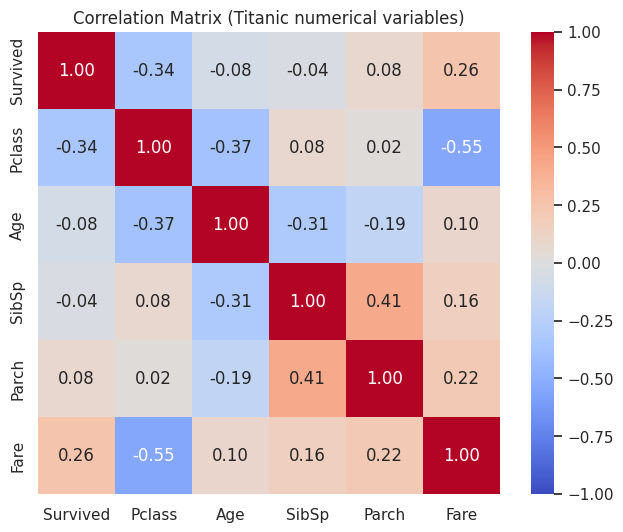

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix (Titanic numerical variables)")
plt.show()

In [ ]:
cov = num_df.cov()
cov.round(3)

,Survived,Pclass,Age,SibSp,Parch,Fare
Survived,0.237,-0.138,-0.551,-0.019,0.032,6.222
Pclass,-0.138,0.699,-4.496,0.077,0.012,-22.830
Age,-0.551,-4.496,211.019,-4.163,-2.344,73.849
SibSp,-0.019,0.077,-4.163,1.216,0.369,8.749
Parch,0.032,0.012,-2.344,0.369,0.650,8.661
Fare,6.222,-22.830,73.849,8.749,8.661,2469.437


In [ ]:
# Strongest pairs (by absolute correlation)
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pairs.reindex(pairs.abs().sort_values(ascending=False).index).round(3).head(6)

,,0
Pclass,Fare,-0.549
SibSp,Parch,0.415
Pclass,Age,-0.369
Survived,Pclass,-0.338
Age,SibSp,-0.308
Survived,Fare,0.257


1. **Strongest positive correlation:** `SibSp` and `Parch` (+0.41), meaning passengers with siblings or spouses often traveled with parents or children. The strongest overall correlation is between `Pclass` and `Fare` (-0.55).

2. **Little or no relationship:** `Age` and `Fare` (+0.10), `Age` and `Survived` (-0.08), and `SibSp` and `Survived` (-0.04), because their correlation values are close to zero.

3. **Difference between Correlation and Covariance:**
   - **Covariance:** Shows the direction in which two variables change together. Its value depends on their units and scales.
   - **Correlation:** Measures the strength and direction of a relationship, ranging from -1 to +1.

4. **Easier to interpret:** Correlation, because it is standardized between -1 and +1, making relationships easier to compare across different variables.

## Task 8 – Statistical Insights

1. **Largest spread:** `Fare`, because its standard deviation is 49.7 and its range is 0–512.

2. **Outliers:** `Fare` because it contain unusually high values.

3. **Related variables:** `Pclass` and `Fare` (correlation: −0.55), and `SibSp` and `Parch` (correlation: +0.41).

4. **Highest average:** `Fare`, with a mean of about 32.2.

5. **Needs preprocessing:** `Cabin` (77% missing), `Age` (20% missing), and `Embarked` (2 missing values). `Fare` is also highly skewed.

## Task 9 – Statistics for Machine Learning

In [ ]:
# Evidence: survival rate by the main categorical features, and correlation with Survived
print(df.groupby("Sex")["Survived"].mean().round(3), "\n")
print(df.groupby("Pclass")["Survived"].mean().round(3), "\n")
print(corr["Survived"].drop("Survived").round(3))

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64 

Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64 

Pclass   -0.338
Age      -0.077
SibSp    -0.035
Parch     0.082
Fare      0.257
Name: Survived, dtype: float64


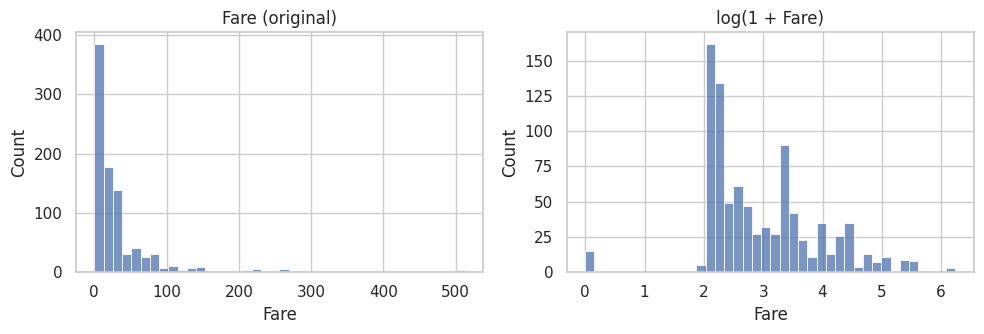

In [ ]:
# Log transform helps the skewed Fare
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(df["Fare"], bins=40, ax=axes[0]).set_title("Fare (original)")
sns.histplot(np.log1p(df["Fare"]), bins=40, ax=axes[1]).set_title("log(1 + Fare)")
plt.tight_layout(); plt.show()

1. **Most useful feature:** `Sex`. About 74% of women survived compared with only 19% of men. `Pclass` is also important, as survival was about 63% in first class versus 24% in third class. `Pclass` has a correlation of approximately -0.34 with `Survived`, while `Fare` has a correlation of +0.26.

2. **Features to remove:** `Cabin`, because approximately 77% of its values are missing. `PassengerId` can also be removed because it is an identifier rather than a meaningful passenger characteristic. `Name` and `Ticket` could be used for feature extraction before removing them.

3. **PCA:** `Fare` would contribute the most to the first principal component before scaling because its variance is approximately 2469. `Pclass` and `Fare` are negatively correlated (-0.55), while `SibSp` and `Parch` are positively correlated (+0.41). After standardization, PCA may combine correlated features into components representing shared information.

4. **Preprocessing steps:**

- **Missing values:** Fill `Age` (177 missing values) with the median and `Embarked` (2 missing values) with the mode. Consider dropping `Cabin` or extracting deck information before removing it.
- **Encoding:** Convert `Sex` and `Embarked` into numerical values using one-hot encoding or suitable binary encoding.
- **Outliers and skewness:** Apply `log1p` to `Fare` because its skewness is approximately 4.8 and it contains extreme values.
- **Scaling:** Standardize numerical features such as `Age`, `Fare`, `SibSp`, and `Parch`, especially before applying PCA.
- **Feature engineering:** Create `FamilySize` by adding `SibSp` and `Parch` and including the passenger. Extract titles such as `Mr`, `Mrs`, and `Miss` from `Name`.
- **Data splitting:** Use a stratified train/test split to preserve the survival class distribution. Fit preprocessing steps on the training set only to prevent data leakage.